In [2]:
# ===== Cell 1: Setup =====
import os, json, glob
from pathlib import Path
from collections import Counter

WORK = Path('/kaggle/working/kidney_project')
for sub in ['data','features','weights','histories','predictions','figures','tables']:
    (WORK/sub).mkdir(parents=True, exist_ok=True)

config_code = """
import os, glob, random
from pathlib import Path
import numpy as np
SEED = 42
WORK = Path('/kaggle/working/kidney_project')
IMG_SIZE = (224, 224)
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    try:
        import tensorflow as tf
        tf.random.set_seed(s)
    except Exception:
        pass

def find_artifact(relpath):
    # 1) look in working folder, 2) look in any attached dataset
    p = WORK / relpath
    if p.exists():
        return p
    hits = glob.glob('/kaggle/input/**/' + relpath, recursive=True)
    if not hits:
        hits = glob.glob('/kaggle/input/**/' + os.path.basename(relpath), recursive=True)
    if hits:
        return Path(hits[0])
    raise FileNotFoundError('Not found in working or input: ' + relpath)
"""
(WORK/'config.py').write_text(config_code)
exec(config_code)

# ---- discover dataset structure (no assumptions about names) ----
structure = {}
for root, dirs, files in os.walk('/kaggle/input'):
    imgs = [f for f in files if f.lower().endswith(IMG_EXTS)]
    if imgs:
        structure[root] = dict(Counter(os.path.splitext(f)[1].lower() for f in imgs))
for k, v in sorted(structure.items()):
    print(f'{k}  ->  {v}  (total {sum(v.values())})')
json.dump(structure, open(WORK/'data'/'dataset_structure.json', 'w'), indent=2)

# ---- environment checks ----
try:
    import tensorflow as tf
    print('\nTensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))
except Exception as e:
    print('TensorFlow problem:', e)
import urllib.request
try:
    urllib.request.urlopen('https://storage.googleapis.com', timeout=8)
    print('Internet: ON')
except Exception as e:
    print('Internet: OFF or blocked ->', e)
print('\nSaved to', WORK)

/kaggle/input/datasets/imtkaggleteam/kidney-stone-classification-and-object-detection/Normal  ->  {'.jpg': 4414}  (total 4414)
/kaggle/input/datasets/imtkaggleteam/kidney-stone-classification-and-object-detection/stone  ->  {'.jpg': 5002}  (total 5002)
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst  ->  {'.jpg': 3709}  (total 3709)
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Normal  ->  {'.jpg': 5077}  (total 5077)
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Stone  ->  {'.jpg': 1377}  (total 1377)
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DAT

In [3]:
# ===== CELL 2 =====
import glob, re, os, json
import pandas as pd
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())

US_ROOT = '/kaggle/input/datasets/imtkaggleteam/kidney-stone-classification-and-object-detection'
CT_ROOT = ('/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/'
           'CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone')

SOURCES = [
    ('US', 'Normal', 0, f'{US_ROOT}/Normal'),
    ('US', 'Stone',  1, f'{US_ROOT}/stone'),
    ('CT', 'Normal', 0, f'{CT_ROOT}/Normal'),
    ('CT', 'Stone',  1, f'{CT_ROOT}/Stone'),
]
EXCLUDED_CT = {'Cyst': 3709, 'Tumor': 2283}   
TRAIN_FRAC = 0.80

def natkey(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', s)]

rows = []
for modality, cname, label, folder in SOURCES:
    files = sorted((f for f in os.listdir(folder) if f.lower().endswith(IMG_EXTS)), key=natkey)
    n = len(files)
    n_train = int(TRAIN_FRAC * n)            
    for r, f in enumerate(files):
        rows.append(dict(path=f'{folder}/{f}', filename=f, modality=modality,
                         class_name=cname, label=label,
                         split='train' if r < n_train else 'test',
                         rank_in_stratum=r))

man = pd.DataFrame(rows)
man.to_csv(WORK/'data'/'manifest.csv', index=False)

print('Total images:', len(man))
print('\nCounts per modality x class x split:')
print(man.groupby(['modality','class_name','split']).size().unstack(fill_value=0))
print('\nTotals per split:'); print(man.split.value_counts())
print('\nTotals per modality x split:'); print(man.groupby(['modality','split']).size().unstack())

print('\nMajority-class baselines on the TEST set (D-04):')
for m in ['CT','US']:
    t = man[(man.modality==m)&(man.split=='test')]
    share_stone = t.label.mean()*100
    print(f'  {m}: n={len(t)}, Stone {share_stone:.2f}%, Normal {100-share_stone:.2f}%, '
          f'majority baseline = {max(share_stone,100-share_stone):.2f}%')
t = man[man.split=='test']
print(f'  ALL: n={len(t)}, Stone {t.label.mean()*100:.2f}%')

print('\nFirst 3 and last 3 file names per stratum (should now be 1,2,3 ... n-2,n-1,n):')
for (m,c), g in man.groupby(['modality','class_name']):
    g = g.sort_values('rank_in_stratum')
    print(f'  {m} {c}: first {list(g.filename.head(3))} | last {list(g.filename.tail(3))}')

json.dump(dict(excluded_ct_classes=EXCLUDED_CT, train_frac=TRAIN_FRAC, seed=SEED,
               assumption='natural numeric order of file names follows acquisition order (unverified)'),
          open(WORK/'data'/'split_info.json','w'), indent=2)
print('\nSaved: data/manifest.csv, data/split_info.json')

Total images: 15870

Counts per modality x class x split:
split                test  train
modality class_name             
CT       Normal      1016   4061
         Stone        276   1101
US       Normal       883   3531
         Stone       1001   4001

Totals per split:
split
train    12694
test      3176
Name: count, dtype: int64

Totals per modality x split:
split     test  train
modality             
CT        1292   5162
US        1884   7532

Majority-class baselines on the TEST set (D-04):
  CT: n=1292, Stone 21.36%, Normal 78.64%, majority baseline = 78.64%
  US: n=1884, Stone 53.13%, Normal 46.87%, majority baseline = 53.13%
  ALL: n=3176, Stone 40.21%

First 3 and last 3 file names per stratum (should now be 1,2,3 ... n-2,n-1,n):
  CT Normal: first ['Normal- (1).jpg', 'Normal- (2).jpg', 'Normal- (3).jpg'] | last ['Normal- (5075).jpg', 'Normal- (5076).jpg', 'Normal- (5077).jpg']
  CT Stone: first ['Stone- (1).jpg', 'Stone- (2).jpg', 'Stone- (3).jpg'] | last ['Stone- (1375).

  train: 500/12694  (1s)
  train: 3000/12694  (4s)
  train: 5500/12694  (7s)
  train: 8000/12694  (10s)
  train: 10500/12694  (15s)
  train: 12694/12694  (20s)
train built: 12694 images in 23s
  test: 500/3176  (9s)
  test: 3000/3176  (52s)
test built: 3176 images in 56s

Train array: (12694, 224, 224) uint8 | rows in meta: 12694
CV fold sizes per modality x class (should be near-equal thirds):
cv_fold                 0     1     2
modality class_name                  
CT       Normal      1354  1354  1353
         Stone        367   367   367
US       Normal      1177  1177  1177
         Stone       1334  1334  1333
Mean grey level per modality x class:
CT Normal    46.5
CT Stone     34.9
US Normal    69.5
US Stone     47.4
dtype: float64


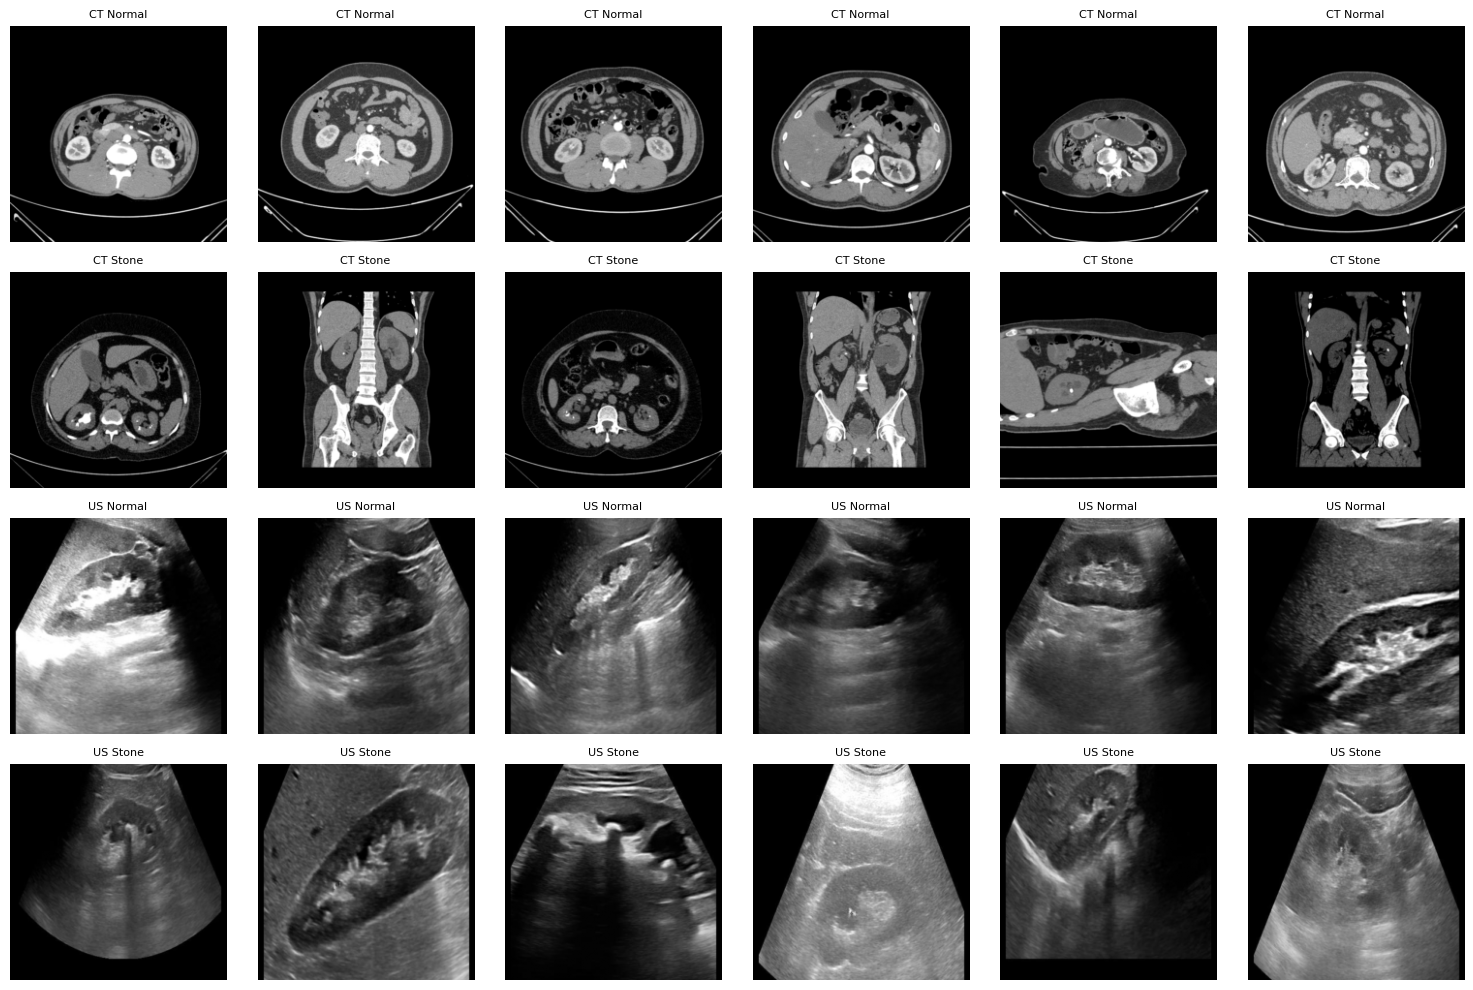

Saved: features/X_train_224.npy, X_test_224.npy; data/meta_train.csv, meta_test.csv, preprocess_config.json


In [8]:
# ===== CELL 3 =====
import glob, json, time
import numpy as np, pandas as pd
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
import matplotlib.pyplot as plt
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())

US_CROP = (0.15, 0.08, 0.85, 0.82)   # fractions x0, y0, x1, y1 (US only)
SIZE, K = 224, 3
PREP = dict(US_CROP=US_CROP, grayscale=True, letterbox_black=True, size=SIZE,
            resize='bilinear', cv_folds=K, cv_type='contiguous, unshuffled, per modality x class, TRAIN only',
            channels_at_model_input='grayscale repeated to 3 channels; backbone scaling applied at feature extraction')
json.dump(PREP, open(WORK/'data'/'preprocess_config.json','w'), indent=2)

man = pd.read_csv(WORK/'data'/'manifest.csv')
def prep(args):
    path, modality = args
    im = Image.open(path).convert('L'); w, h = im.size
    if modality == 'US':
        im = im.crop((int(US_CROP[0]*w), int(US_CROP[1]*h), int(US_CROP[2]*w), int(US_CROP[3]*h)))
        w, h = im.size
    s = max(w, h)
    canvas = Image.new('L', (s, s), 0)
    canvas.paste(im, ((s-w)//2, (s-h)//2))
    return np.asarray(canvas.resize((SIZE, SIZE), Image.BILINEAR), dtype=np.uint8)

for split in ['train', 'test']:
    meta = man[man.split == split].reset_index(drop=True)
    if split == 'train':
        meta['cv_fold'] = 0
        for _, g in meta.groupby(['modality', 'class_name']):
            r = g.rank_in_stratum.rank(method='first').values - 1
            meta.loc[g.index, 'cv_fold'] = np.minimum((r*K//len(g)).astype(int), K-1)
    else:
        meta['cv_fold'] = -1
    meta.to_csv(WORK/'data'/f'meta_{split}.csv', index=False)

    out = WORK/'features'/f'X_{split}_224.npy'
    done = WORK/'features'/f'X_{split}_224.done'
    if out.exists() and done.exists():
        print(split, 'already built:', np.load(out, mmap_mode='r').shape); continue
    arr = np.lib.format.open_memmap(out, mode='w+', dtype=np.uint8, shape=(len(meta), SIZE, SIZE))
    t0 = time.time()
    CH = 500
    for a in range(0, len(meta), CH):
        part = meta.iloc[a:a+CH]
        with ThreadPoolExecutor(4) as ex:
            res = list(ex.map(prep, zip(part.path, part.modality)))
        arr[a:a+len(res)] = np.stack(res)
        if (a // CH) % 5 == 0: print(f'  {split}: {a+len(res)}/{len(meta)}  ({time.time()-t0:.0f}s)')
    arr.flush(); del arr; done.write_text('ok')
    print(split, 'built:', len(meta), 'images in', f'{time.time()-t0:.0f}s')

# ---- checks ----
Xtr = np.load(WORK/'features'/'X_train_224.npy', mmap_mode='r')
mtr = pd.read_csv(WORK/'data'/'meta_train.csv')
print('\nTrain array:', Xtr.shape, Xtr.dtype, '| rows in meta:', len(mtr))
print('CV fold sizes per modality x class (should be near-equal thirds):')
print(mtr.groupby(['modality','class_name','cv_fold']).size().unstack())
print('Mean grey level per modality x class:')
print(pd.Series({f'{m} {c}': float(Xtr[g.index.values[:300]].mean()) for (m,c), g in mtr.groupby(['modality','class_name'])}).round(1))

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for row, ((m, c), g) in enumerate(mtr.groupby(['modality','class_name'])):
    for col, i in enumerate(g.sample(6, random_state=SEED).index):
        axes[row, col].imshow(Xtr[i], cmap='gray', vmin=0, vmax=255); axes[row, col].axis('off')
        axes[row, col].set_title(f'{m} {c}', fontsize=8)
plt.tight_layout(); plt.show()
print('Saved: features/X_train_224.npy, X_test_224.npy; data/meta_train.csv, meta_test.csv, preprocess_config.json')

In [12]:
# ===== Cell 4 =====
import glob
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())

helper_code = '''
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, roc_auc_score, precision_recall_fscore_support

def metrics(y, p, s, mod):
    y, p, s, mod = map(np.asarray, (y, p, s, mod))
    out = {}
    for name, m in [('all', np.ones(len(y), bool)), ('CT', mod == 'CT'), ('US', mod == 'US')]:
        yt, yp, ss = y[m], p[m], s[m]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        pr, rc, f1, _ = precision_recall_fscore_support(yt, yp, labels=[1], zero_division=0)
        out[name] = dict(n=len(yt), acc=100*(tp+tn)/len(yt), balanced=100*balanced_accuracy_score(yt, yp),
                         majority_baseline=100*max(yt.mean(), 1-yt.mean()), sensitivity=100*tp/max(tp+fn, 1),
                         specificity=100*tn/max(tn+fp, 1), precision=100*pr[0], f1=100*f1[0],
                         auc=roc_auc_score(yt, ss) if len(set(yt)) > 1 else np.nan, FP=int(fp), FN=int(fn))
    return pd.DataFrame(out).T

def show_results(title, tr, te):
    # tr, te = dicts with y_true, y_pred, score, modality arrays
    mt, me = metrics(tr['y_true'], tr['y_pred'], tr['score'], tr['modality']), metrics(te['y_true'], te['y_pred'], te['score'], te['modality'])
    print(f'--- {title}: TRAIN ---'); print(mt.round(2).to_string())
    print(f'--- {title}: TEST ---');  print(me.round(2).to_string())
    print(f"Train-test gap (all): {mt.loc['all','acc']-me.loc['all','acc']:.2f} points")
    fig, axes = plt.subplots(2, 3, figsize=(11, 7))
    for r, (nm, d) in enumerate([('train', tr), ('test', te)]):
        for c, g in enumerate(['all', 'CT', 'US']):
            m = np.ones(len(d['y_true']), bool) if g == 'all' else (np.asarray(d['modality']) == g)
            cm = confusion_matrix(np.asarray(d['y_true'])[m], np.asarray(d['y_pred'])[m], labels=[0, 1])
            ax = axes[r, c]; ax.imshow(cm, cmap='Blues')
            for i in range(2):
                for j in range(2): ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=11)
            ax.set_xticks([0, 1]); ax.set_xticklabels(['Normal', 'Stone']); ax.set_yticks([0, 1]); ax.set_yticklabels(['Normal', 'Stone'])
            ax.set_title(f'{nm} - {g}', fontsize=10); ax.set_xlabel('predicted'); ax.set_ylabel('actual')
    fig.suptitle(title); plt.tight_layout(); plt.show()
    return mt, me
'''
(WORK/'helpers_eval.py').write_text(helper_code)
exec(helper_code)
print('helpers_eval.py saved')

helpers_eval.py saved


Epoch 1/2
397/397 - 72s - 182ms/step - accuracy: 0.7200 - loss: 0.5483
Epoch 2/2
397/397 - 61s - 153ms/step - accuracy: 0.7814 - loss: 0.4495
Epoch 1/5
397/397 - 322s - 812ms/step - accuracy: 0.8425 - loss: 0.3516
Epoch 2/5
397/397 - 265s - 667ms/step - accuracy: 0.9443 - loss: 0.1454
Epoch 3/5
397/397 - 265s - 668ms/step - accuracy: 0.9679 - loss: 0.0893
Epoch 4/5
397/397 - 265s - 668ms/step - accuracy: 0.9799 - loss: 0.0566
Epoch 5/5
397/397 - 265s - 668ms/step - accuracy: 0.9824 - loss: 0.0478
fine-tuning done in 25.4 min
saved feat_densenet121fte5_train.npy
saved feat_densenet121fte5_test.npy
--- Fine-tuned DenseNet121 (5 Stage B epochs) alone (sigmoid output): TRAIN ---
           n    acc  balanced  majority_baseline  sensitivity  specificity  precision     f1  auc     FP   FN
all  12694.0  98.90     99.08              59.81        100.0        98.17      97.35  98.66  1.0  139.0  0.0
CT    5162.0  98.80     99.24              78.67        100.0        98.47      94.67  97.26  1.

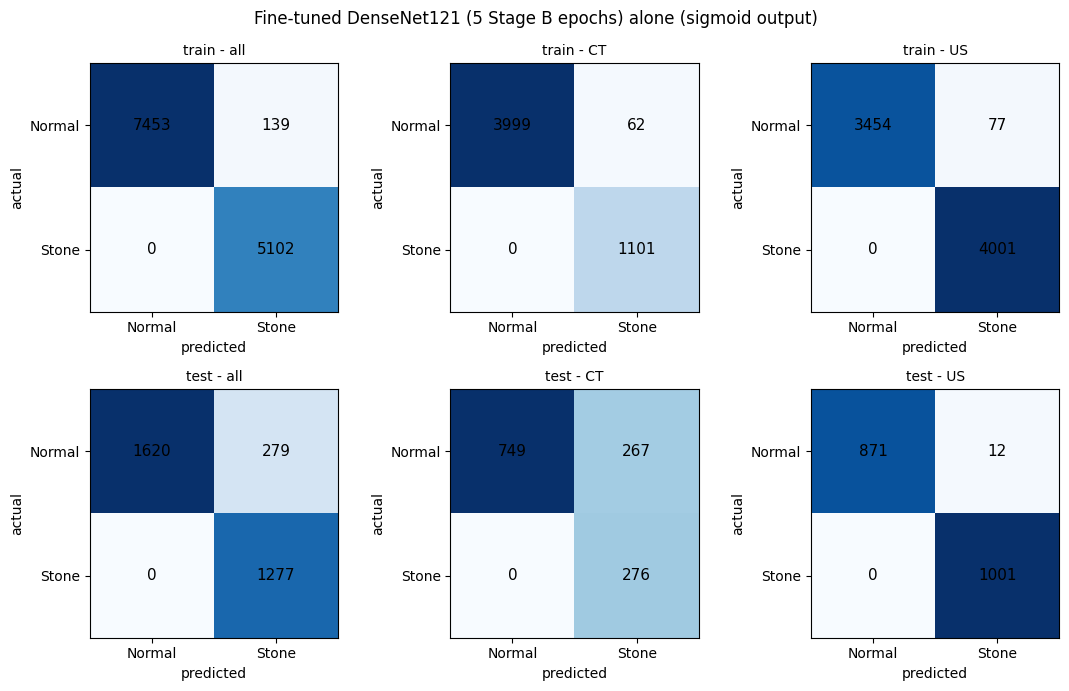

In [32]:
# ===== Cell 5: finetune_densenet121 =====
import glob, time
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as pp
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())
exec(open(WORK/'helpers_eval.py').read())
set_seed(); tf.keras.utils.set_random_seed(SEED)

TAG, FEAT, BATCH, EPOCHS_B = 'ft_densenet121_e5', 'densenet121fte5', 32, 5
mtr = pd.read_csv(WORK/'data'/'meta_train.csv'); mte = pd.read_csv(WORK/'data'/'meta_test.csv')
Xtr = np.load(WORK/'features'/'X_train_224.npy'); Xte = np.load(WORK/'features'/'X_test_224.npy')
ytr, yte = mtr.label.values.astype('float32'), mte.label.values
n0, n1 = (ytr == 0).sum(), (ytr == 1).sum(); cw = {0: len(ytr)/(2*n0), 1: len(ytr)/(2*n1)}

base = DenseNet121(weights='imagenet', include_top=False, pooling='avg', input_shape=(224, 224, 3))
inp = layers.Input((224, 224, 3))
x = layers.RandomFlip('horizontal')(inp); x = layers.RandomRotation(0.04)(x); x = layers.RandomZoom(0.1)(x)
x = layers.Lambda(lambda t: pp(t))(x)
x = base(x, training=False)
x = layers.Dropout(0.5)(x); out = layers.Dense(1, activation='sigmoid')(x)
model = tf.keras.Model(inp, out)

def ds(X, y, shuffle):
    d = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle: d = d.shuffle(4096, seed=SEED)
    return d.batch(BATCH).map(lambda a, b: (tf.repeat(tf.cast(a, tf.float32)[..., None], 3, -1), b)).prefetch(2)

wfile = WORK/'weights'/f'{TAG}.weights.h5'
if wfile.exists():
    model.load_weights(wfile); print('weights loaded from file (training skipped)')
else:
    t0 = time.time()
    base.trainable = False
    model.compile(tf.keras.optimizers.Adam(1e-3), 'binary_crossentropy', metrics=['accuracy'])
    hA = model.fit(ds(Xtr, ytr, True), epochs=2, class_weight=cw, verbose=2)
    base.trainable = True
    model.compile(tf.keras.optimizers.Adam(2e-5), 'binary_crossentropy', metrics=['accuracy'])
    hB = model.fit(ds(Xtr, ytr, True), epochs=EPOCHS_B, class_weight=cw, verbose=2)
    model.save_weights(wfile)
    pd.DataFrame({k: hA.history[k] + hB.history[k] for k in ['loss', 'accuracy']}).to_csv(WORK/'histories'/f'{TAG}_history.csv', index=False)
    print(f'fine-tuning done in {(time.time()-t0)/60:.1f} min')

def feats(X):
    o = []
    for a in range(0, len(X), 64):
        o.append(base(pp(np.repeat(X[a:a+64].astype('float32')[..., None], 3, -1)), training=False).numpy())
    return np.concatenate(o)
for nm, X in [('train', Xtr), ('test', Xte)]:
    f = WORK/'features'/f'feat_{FEAT}_{nm}.npy'
    if not f.exists(): np.save(f, feats(X)); print('saved', f.name)

res = {}
for nm, X, y, meta in [('train', Xtr, ytr.astype(int), mtr), ('test', Xte, yte, mte)]:
    s = model.predict(ds(X, np.zeros(len(X), 'float32'), False), verbose=0).ravel()
    res[nm] = dict(y_true=y, y_pred=(s > 0.5).astype(int), score=s, modality=meta.modality.values)
    pd.DataFrame(res[nm]).to_csv(WORK/'predictions'/f'pred_{TAG}_{nm}.csv', index=False)
mt, me = show_results('Fine-tuned DenseNet121 (5 Stage B epochs) alone (sigmoid output)', res['train'], res['test'])
pd.concat({'train': mt, 'test': me}).to_csv(WORK/'tables'/f'{TAG}_metrics.csv')

pixel features: (12694, 4096) (3176, 4096)
CV grid done in 3064s
                val_acc       train_acc      
                   mean   std      mean   std
C    gamma_mult                              
0.01 0.1          69.11  8.99     72.53  3.40
     1.0          75.59  4.24     80.89  0.65
0.10 0.1          72.67  3.20     83.23  1.88
     1.0          78.59  8.18     94.06  0.12
1.00 0.1          77.52  5.10     93.96  0.62
     1.0          81.67  5.12     99.23  0.21

Selected by mean CV accuracy: C=1.0, gamma_mult=1.0, CV acc=81.67
--- SVM solo on 64x64 grayscale pixels (C=1.0, gamma x1.0): TRAIN ---
           n    acc  balanced  majority_baseline  sensitivity  specificity  precision     f1  auc    FP    FN
all  12694.0  99.38     99.44              59.81        99.76        99.12      98.70  99.23  1.0  67.0  12.0
CT    5162.0  99.92     99.82              78.67        99.64       100.00     100.00  99.82  1.0   0.0   4.0
US    7532.0  99.00     98.95              53.12      

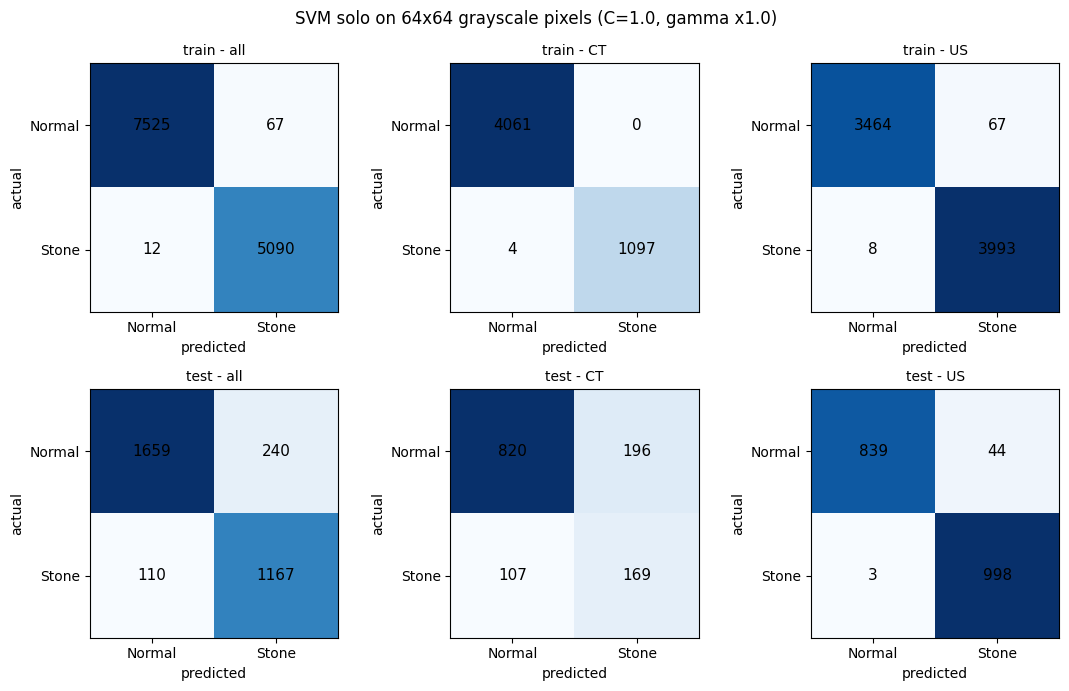

In [40]:
# ===== Cell 6: svm_solo_pixels (64x64 grayscale -> class-weighted RBF-SVM; 3-fold CV in TRAIN) =====
import glob, time, json, itertools
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import tensorflow as tf
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())
exec(open(WORK/'helpers_eval.py').read())

NAME = 'pixels64'; TAG = f'svmw_{NAME}_cv3'
GRID_C, GRID_GM = [0.01, 0.1, 1], [1.0, 0.1]

def small(split):
    f = WORK/'features'/f'feat_{NAME}_{split}.npy'
    if f.exists(): return np.load(f)
    X = np.load(WORK/'features'/f'X_{split}_224.npy', mmap_mode='r'); out = []
    for a in range(0, len(X), 512):
        xb = tf.image.resize(np.asarray(X[a:a+512], 'float32')[..., None], (64, 64), method='area').numpy()
        out.append(xb.reshape(len(xb), -1) / 255.0)
    F = np.concatenate(out).astype('float32'); np.save(f, F); return F
Xtr, Xte = small('train'), small('test'); print('pixel features:', Xtr.shape, Xte.shape)
mtr = pd.read_csv(WORK/'data'/'meta_train.csv'); mte = pd.read_csv(WORK/'data'/'meta_test.csv')
ytr, yte, folds, d = mtr.label.values, mte.label.values, mtr.cv_fold.values, Xtr.shape[1]

def one_fit(C, gm, f):
    a, b = folds != f, folds == f
    sc = StandardScaler().fit(Xtr[a]); A, B = sc.transform(Xtr[a]), sc.transform(Xtr[b])
    clf = SVC(kernel='rbf', C=C, gamma=gm/(d*A.var()), class_weight='balanced').fit(A, ytr[a])
    return dict(C=C, gamma_mult=gm, fold=f, val_acc=100*clf.score(B, ytr[b]), train_acc=100*clf.score(A, ytr[a]))

cvfile = WORK/'tables'/f'{TAG}_cvtable.csv'
if cvfile.exists():
    cv = pd.read_csv(cvfile); print('CV table loaded from file')
else:
    t0 = time.time()
    cv = pd.DataFrame(Parallel(n_jobs=4)(delayed(one_fit)(C, gm, f) for C, gm, f in itertools.product(GRID_C, GRID_GM, range(3))))
    cv.to_csv(cvfile, index=False); print(f'CV grid done in {time.time()-t0:.0f}s')
print(cv.groupby(['C', 'gamma_mult'])[['val_acc', 'train_acc']].agg(['mean', 'std']).round(2).to_string())

best = cv.groupby(['C', 'gamma_mult']).val_acc.mean().reset_index().sort_values(['val_acc', 'C', 'gamma_mult'], ascending=[False, True, True]).iloc[0]
C_best, gm_best = float(best.C), float(best.gamma_mult)
print(f'\nSelected by mean CV accuracy: C={C_best}, gamma_mult={gm_best}, CV acc={best.val_acc:.2f}')

sc = StandardScaler().fit(Xtr); A, B = sc.transform(Xtr), sc.transform(Xte)
clf = SVC(kernel='rbf', C=C_best, gamma=gm_best/(d*A.var()), class_weight='balanced').fit(A, ytr)
res = {}
for nm, M, y, meta in [('train', A, ytr, mtr), ('test', B, yte, mte)]:
    s = clf.decision_function(M)
    res[nm] = dict(y_true=y, y_pred=(s > 0).astype(int), score=s, modality=meta.modality.values)
    pd.DataFrame(res[nm]).to_csv(WORK/'predictions'/f'pred_{TAG}_{nm}.csv', index=False)
json.dump(dict(C=C_best, gamma_mult=gm_best, cv_acc=float(best.val_acc), seed=SEED), open(WORK/'tables'/f'{TAG}_best.json', 'w'))
mt, me = show_results(f'SVM solo on 64x64 grayscale pixels (C={C_best}, gamma x{gm_best})', res['train'], res['test'])
pd.concat({'train': mt, 'test': me}).to_csv(WORK/'tables'/f'{TAG}_metrics.csv')

CV grid done in 244s
                val_acc       train_acc      
                   mean   std      mean   std
C    gamma_mult                              
0.01 0.1          99.28  0.87     99.37  0.39
     1.0          99.03  0.96     99.15  0.44
0.10 0.1          99.39  0.82     99.50  0.31
     1.0          99.24  0.86     99.76  0.10
1.00 0.1          99.46  0.75     99.90  0.06
     1.0          99.39  0.80    100.00  0.01

Selected by mean CV accuracy: C=1.0, gamma_mult=0.1, CV acc=99.46
--- Class-weighted SVM on 5-epoch fine-tuned DenseNet121 (C=1.0, gamma x0.1): TRAIN ---
           n     acc  balanced  majority_baseline  sensitivity  specificity  precision      f1  auc    FP   FN
all  12694.0   99.89      99.9              59.81        99.98        99.83      99.75   99.86  1.0  13.0  1.0
CT    5162.0  100.00     100.0              78.67       100.00       100.00     100.00  100.00  1.0   0.0  0.0
US    7532.0   99.81      99.8              53.12        99.98        99.63  

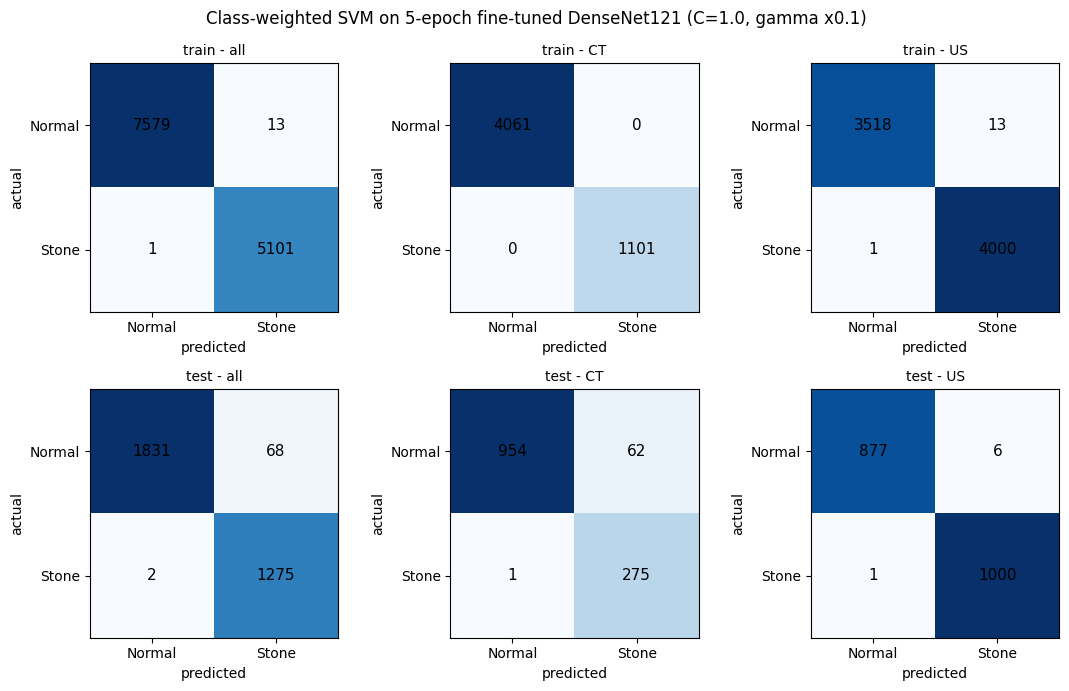

In [33]:
# ===== Cell 7: svm_densenet121fte5 (class-weighted) =====
import glob, time, json, itertools
import numpy as np, pandas as pd
from joblib import Parallel, delayed
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())
exec(open(WORK/'helpers_eval.py').read())

NAME = 'densenet121fte5'; TAG = f'svmw_{NAME}_cv3'
GRID_C, GRID_GM = [0.01, 0.1, 1], [1.0, 0.1]

Xtr = np.load(WORK/'features'/f'feat_{NAME}_train.npy'); Xte = np.load(WORK/'features'/f'feat_{NAME}_test.npy')
mtr = pd.read_csv(WORK/'data'/'meta_train.csv'); mte = pd.read_csv(WORK/'data'/'meta_test.csv')
ytr, yte, folds, d = mtr.label.values, mte.label.values, mtr.cv_fold.values, Xtr.shape[1]

def one_fit(C, gm, f):
    a, b = folds != f, folds == f
    sc = StandardScaler().fit(Xtr[a]); A, B = sc.transform(Xtr[a]), sc.transform(Xtr[b])
    clf = SVC(kernel='rbf', C=C, gamma=gm/(d*A.var()), class_weight='balanced').fit(A, ytr[a])
    return dict(C=C, gamma_mult=gm, fold=f, val_acc=100*clf.score(B, ytr[b]), train_acc=100*clf.score(A, ytr[a]))

cvfile = WORK/'tables'/f'{TAG}_cvtable.csv'
if cvfile.exists():
    cv = pd.read_csv(cvfile); print('CV table loaded from file')
else:
    t0 = time.time()
    cv = pd.DataFrame(Parallel(n_jobs=4)(delayed(one_fit)(C, gm, f) for C, gm, f in itertools.product(GRID_C, GRID_GM, range(3))))
    cv.to_csv(cvfile, index=False); print(f'CV grid done in {time.time()-t0:.0f}s')
print(cv.groupby(['C', 'gamma_mult'])[['val_acc', 'train_acc']].agg(['mean', 'std']).round(2).to_string())

best = cv.groupby(['C', 'gamma_mult']).val_acc.mean().reset_index().sort_values(['val_acc', 'C', 'gamma_mult'], ascending=[False, True, True]).iloc[0]
C_best, gm_best = float(best.C), float(best.gamma_mult)
print(f'\nSelected by mean CV accuracy: C={C_best}, gamma_mult={gm_best}, CV acc={best.val_acc:.2f}')

sc = StandardScaler().fit(Xtr); A, B = sc.transform(Xtr), sc.transform(Xte)
clf = SVC(kernel='rbf', C=C_best, gamma=gm_best/(d*A.var()), class_weight='balanced').fit(A, ytr)
res = {}
for nm, M, y, meta in [('train', A, ytr, mtr), ('test', B, yte, mte)]:
    s = clf.decision_function(M)
    res[nm] = dict(y_true=y, y_pred=(s > 0).astype(int), score=s, modality=meta.modality.values)
    pd.DataFrame(res[nm]).to_csv(WORK/'predictions'/f'pred_{TAG}_{nm}.csv', index=False)
json.dump(dict(C=C_best, gamma_mult=gm_best, cv_acc=float(best.val_acc), seed=SEED), open(WORK/'tables'/f'{TAG}_best.json', 'w'))
mt, me = show_results(f'Class-weighted SVM on 5-epoch fine-tuned DenseNet121 (C={C_best}, gamma x{gm_best})', res['train'], res['test'])
pd.concat({'train': mt, 'test': me}).to_csv(WORK/'tables'/f'{TAG}_metrics.csv')

{'model': 'Hybrid SVM (fine-tuned DenseNet121 features)', 'frac': 0.25, 'n': 3172, 'train': 99.96847414880202, 'test': 96.85138539042822}
{'model': 'Hybrid SVM (fine-tuned DenseNet121 features)', 'frac': 0.5, 'n': 6345, 'train': 99.96847911741528, 'test': 97.63853904282117}
{'model': 'Hybrid SVM (fine-tuned DenseNet121 features)', 'frac': 0.75, 'n': 9518, 'train': 99.95797436436226, 'test': 97.63853904282117}
{'model': 'Hybrid SVM (fine-tuned DenseNet121 features)', 'frac': 1.0, 'n': 12694, 'train': 99.88971167480699, 'test': 97.79596977329975}
{'model': 'SVM solo (64x64 pixels)', 'frac': 0.25, 'n': 3172, 'train': 99.24337957124843, 'test': 80.79345088161209}
{'model': 'SVM solo (64x64 pixels)', 'frac': 0.5, 'n': 6345, 'train': 99.4956658786446, 'test': 84.09949622166248}
{'model': 'SVM solo (64x64 pixels)', 'frac': 0.75, 'n': 9518, 'train': 99.46417314561883, 'test': 90.05037783375315}
{'model': 'SVM solo (64x64 pixels)', 'frac': 1.0, 'n': 12694, 'train': 99.37765873641091, 'test': 88

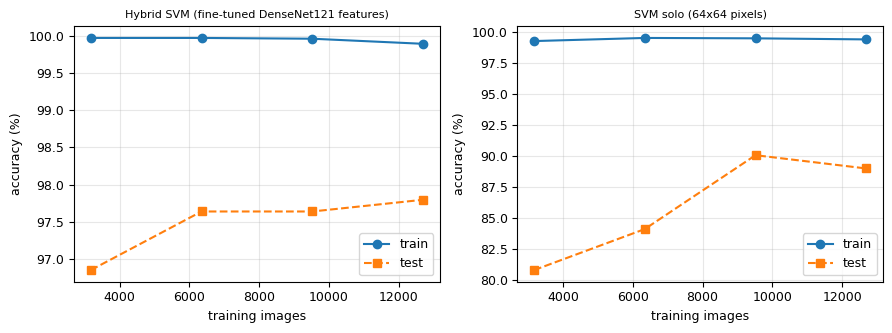

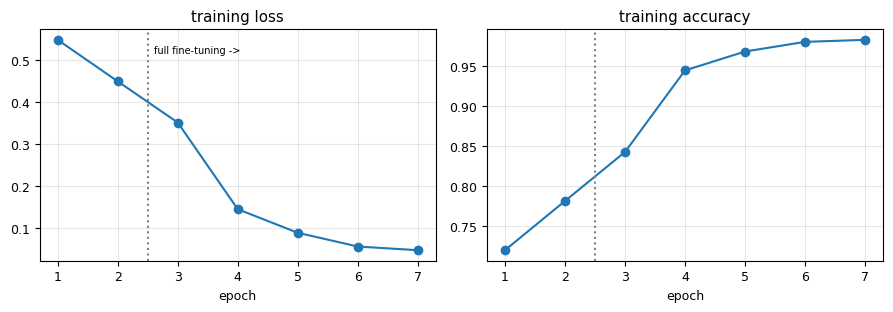

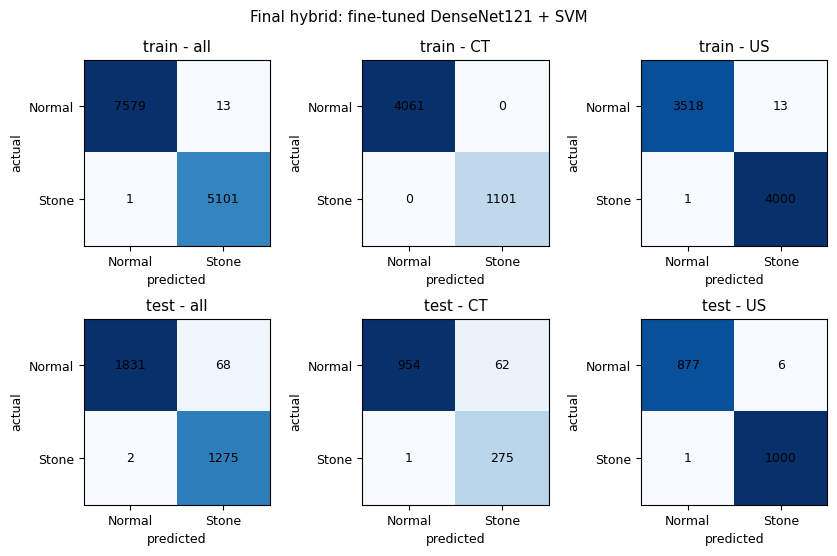

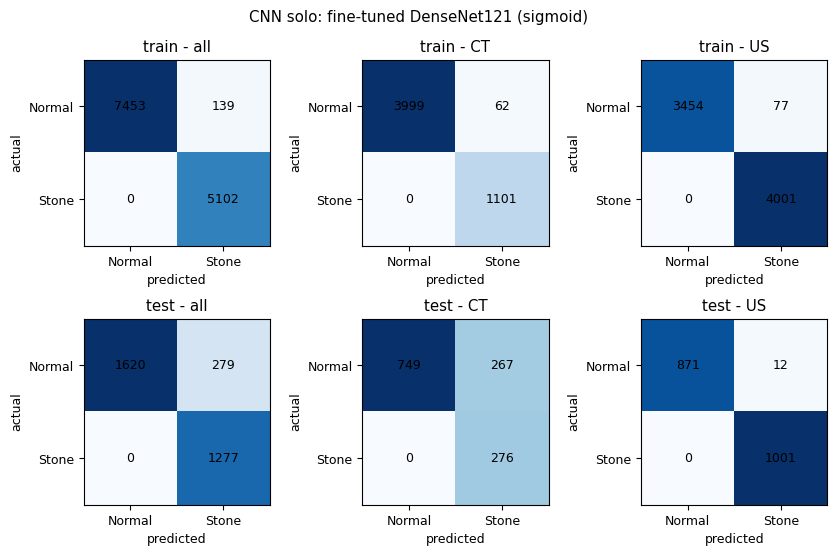

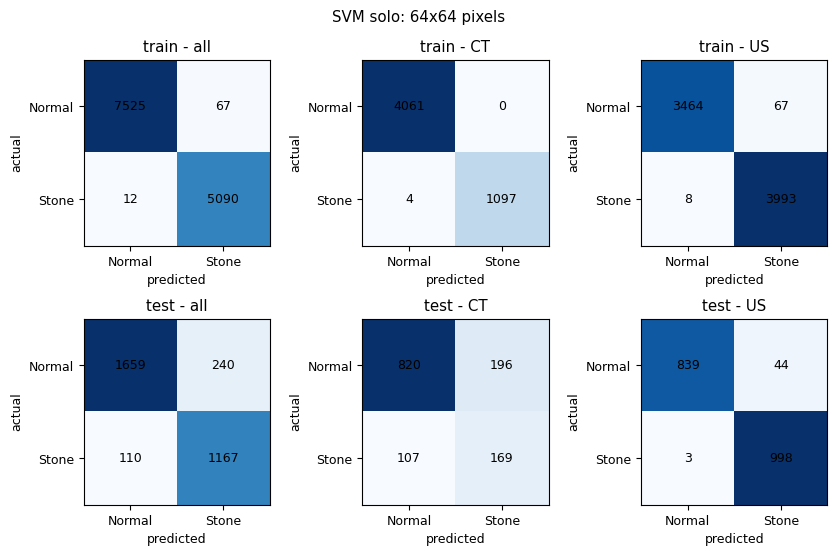

saved to /kaggle/working/kidney_project/figures


In [41]:
# ===== Cell 8: curves_and_matrices (final hybrid, CNN solo, SVM solo; saves PDFs) =====
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())
plt.rcParams.update({'font.size': 9})
mtr = pd.read_csv(WORK/'data'/'meta_train.csv'); mte = pd.read_csv(WORK/'data'/'meta_test.csv')
ytr, yte = mtr.label.values, mte.label.values
FIG = WORK/'figures'

# ---- 1. SVM learning curves (train & test accuracy vs share of training data) ----
def learning_curve(name, feat):
    best = json.load(open(WORK/'tables'/f'svmw_{feat}_cv3_best.json'))
    Xtr = np.load(WORK/'features'/f'feat_{feat}_train.npy'); Xte = np.load(WORK/'features'/f'feat_{feat}_test.npy')
    rank = mtr.groupby(['modality', 'class_name']).rank_in_stratum.rank(pct=True).values   # position inside each stratum, sorted order
    rows = []
    for frac in [0.25, 0.5, 0.75, 1.0]:
        k = rank <= frac + 1e-9
        sc = StandardScaler().fit(Xtr[k]); A = sc.transform(Xtr[k])
        clf = SVC(kernel='rbf', C=best['C'], gamma=best['gamma_mult']/(Xtr.shape[1]*A.var()), class_weight='balanced').fit(A, ytr[k])
        rows.append(dict(model=name, frac=frac, n=int(k.sum()), train=100*clf.score(A, ytr[k]), test=100*clf.score(sc.transform(Xte), yte)))
        print(rows[-1])
    return pd.DataFrame(rows)
lc = pd.concat([learning_curve('Hybrid SVM (fine-tuned DenseNet121 features)', 'densenet121fte5'),
                learning_curve('SVM solo (64x64 pixels)', 'pixels64')])
lc.round(2).to_csv(WORK/'tables'/'learning_curves_svm.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, (nm, g) in zip(axes, lc.groupby('model', sort=False)):
    ax.plot(g.n, g.train, 'o-', label='train'); ax.plot(g.n, g.test, 's--', label='test')
    ax.set_title(nm, fontsize=8); ax.set_xlabel('training images'); ax.set_ylabel('accuracy (%)'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG/'learning_curves_svm.pdf'); plt.show()

# ---- 2. CNN training curves (training only; no validation split is used) ----
h = pd.read_csv(WORK/'histories'/'ft_densenet121_e5_history.csv'); ep = np.arange(1, len(h)+1)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, k, t in [(ax[0], 'loss', 'training loss'), (ax[1], 'accuracy', 'training accuracy')]:
    a.plot(ep, h[k], 'o-'); a.axvline(2.5, color='gray', ls=':'); a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=.3)
ax[0].text(2.6, ax[0].get_ylim()[1]*0.9, 'full fine-tuning ->', fontsize=7)
plt.tight_layout(); plt.savefig(FIG/'cnn_training_curves.pdf'); plt.show()

# ---- 3. confusion matrices, one figure per model ----
def cm_figure(tag, title, fname):
    tr = pd.read_csv(WORK/'predictions'/f'pred_{tag}_train.csv'); te = pd.read_csv(WORK/'predictions'/f'pred_{tag}_test.csv')
    fig, axes = plt.subplots(2, 3, figsize=(8.5, 5.6))
    for r, (nm, d) in enumerate([('train', tr), ('test', te)]):
        for c, g in enumerate(['all', 'CT', 'US']):
            m = np.ones(len(d), bool) if g == 'all' else (d.modality.values == g)
            cm = confusion_matrix(d.y_true[m], d.y_pred[m], labels=[0, 1]); ax = axes[r, c]; ax.imshow(cm, cmap='Blues')
            for i in range(2):
                for j in range(2): ax.text(j, i, cm[i, j], ha='center', va='center')
            ax.set_xticks([0, 1]); ax.set_xticklabels(['Normal', 'Stone']); ax.set_yticks([0, 1]); ax.set_yticklabels(['Normal', 'Stone'])
            ax.set_title(f'{nm} - {g}'); ax.set_xlabel('predicted'); ax.set_ylabel('actual')
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG/fname); plt.show()
cm_figure('svmw_densenet121fte5_cv3', 'Final hybrid: fine-tuned DenseNet121 + SVM', 'cm_hybrid.pdf')
cm_figure('ft_densenet121_e5', 'CNN solo: fine-tuned DenseNet121 (sigmoid)', 'cm_cnn_solo.pdf')
cm_figure('svmw_pixels64_cv3', 'SVM solo: 64x64 pixels', 'cm_svm_solo.pdf')
print('saved to', FIG)

max |TF SVM - sklearn| : 1.9606617662759618e-08
max |fresh features - saved features| : 2.0503998e-05
sign agreement with saved test predictions: 1.0
ring width 34px covers 51.5% of the image
                 count   mean    std
modality pred                       
CT       Normal    298  0.545  0.235
         Stone     102  0.445  0.198
US       Normal    192  0.723  0.134
         Stone     208  0.957  0.124


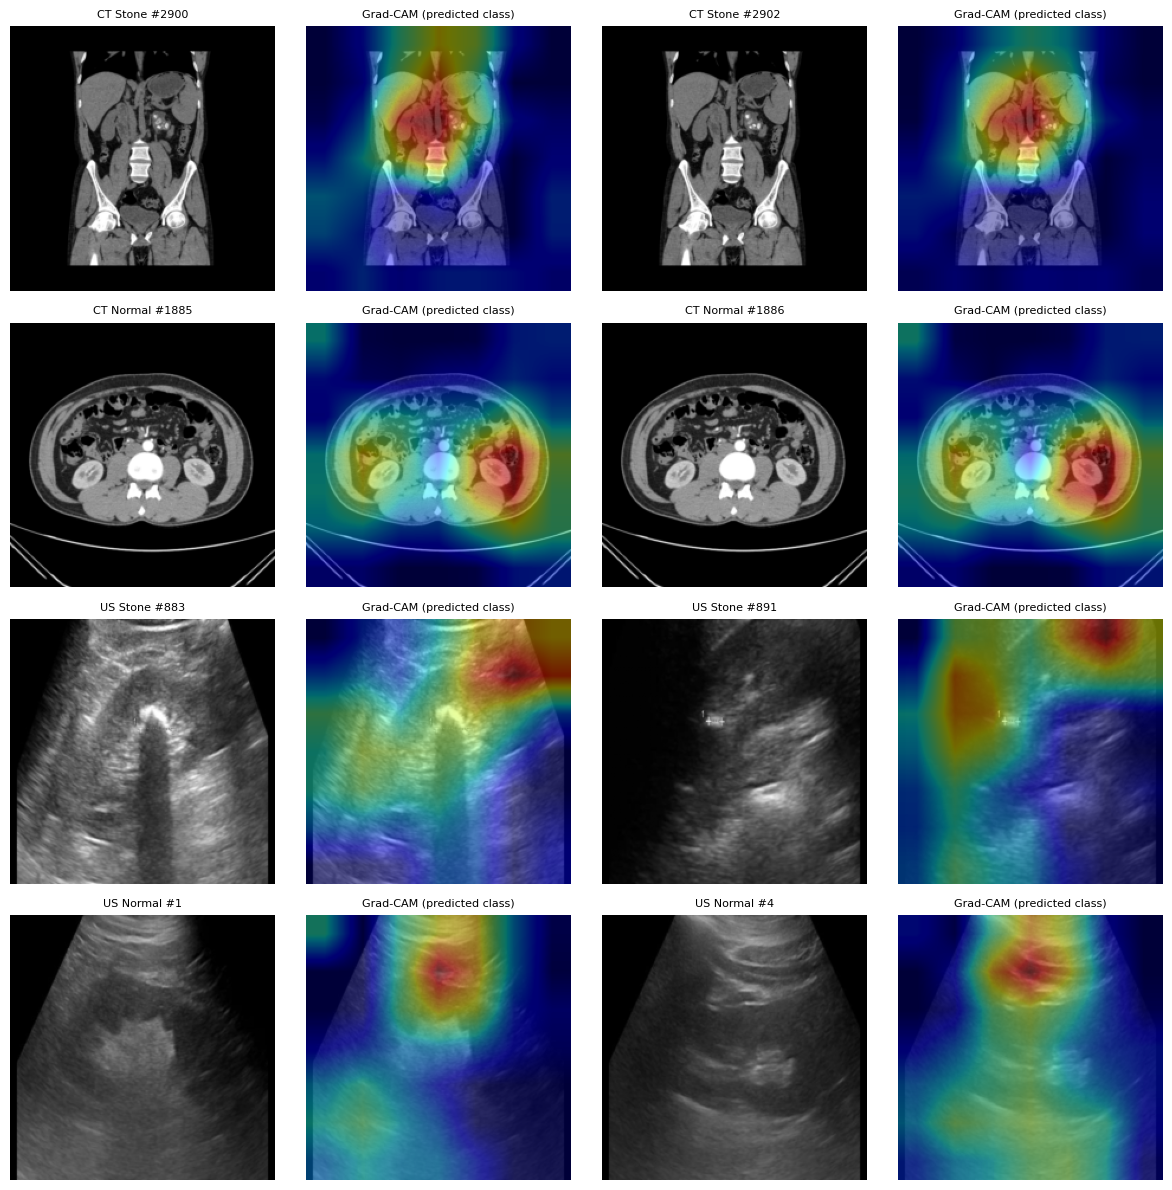

errors among the 800 sampled images: 16 (showing up to 6)


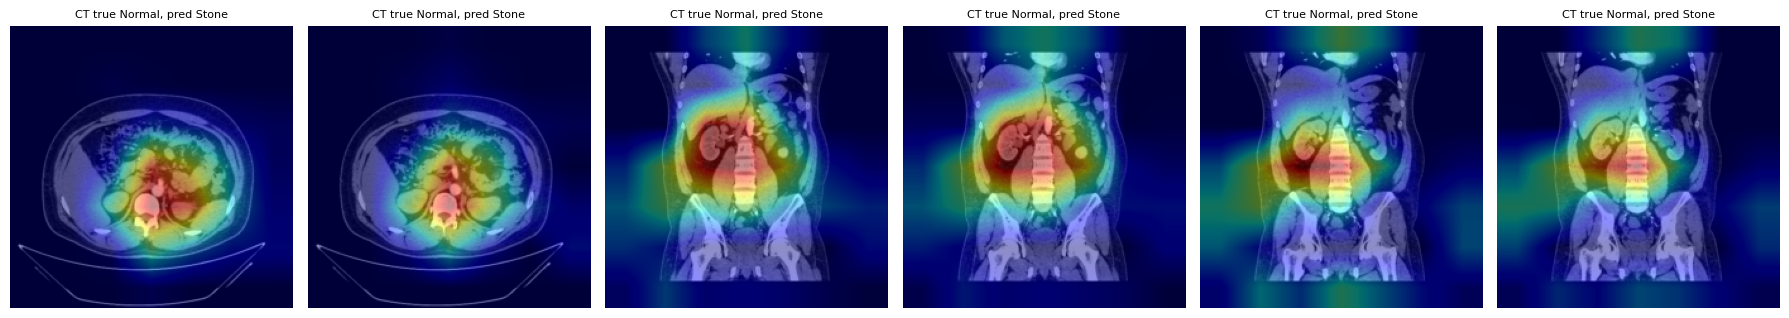

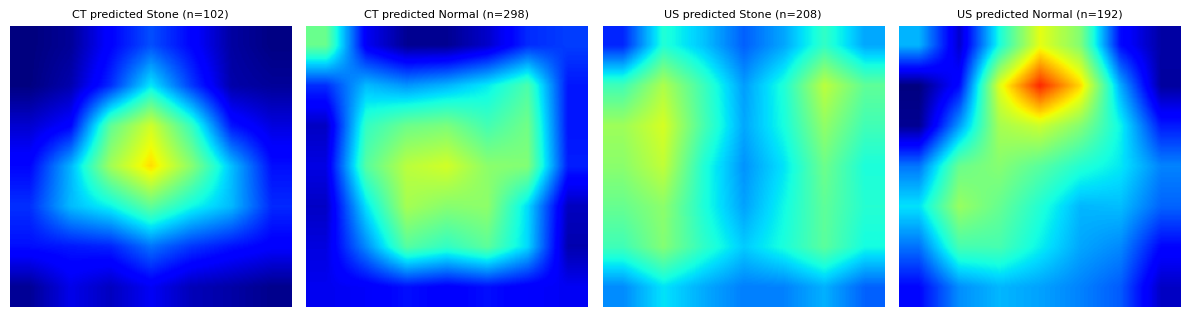

In [35]:
# ===== Cell 9: gradcam_svm (needs s10c weights + s11d best.json; GPU helpful) =====
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())

code = '''
import numpy as np, pandas as pd, tensorflow as tf, json
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as pp
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

def load_all(WORK, SEED):
    base = DenseNet121(weights=None, include_top=False, pooling='avg', input_shape=(224, 224, 3))
    inp = layers.Input((224, 224, 3))
    x = layers.RandomFlip('horizontal')(inp); x = layers.RandomRotation(0.04)(x); x = layers.RandomZoom(0.1)(x)
    x = layers.Lambda(lambda t: pp(t))(x); x = base(x, training=False)
    x = layers.Dropout(0.5)(x); out = layers.Dense(1, activation='sigmoid')(x)
    model = tf.keras.Model(inp, out)
    model.load_weights(WORK/'weights'/'ft_densenet121_e5.weights.h5')      # same weights as s10c
    fm = tf.keras.Model(base.input, [base.get_layer('relu').output, base.output])
    Ftr = np.load(WORK/'features'/'feat_densenet121fte5_train.npy')
    mtr = pd.read_csv(WORK/'data'/'meta_train.csv')
    best = json.load(open(WORK/'tables'/'svmw_densenet121fte5_cv3_best.json'))
    sc = StandardScaler().fit(Ftr); A = sc.transform(Ftr)
    gamma = best['gamma_mult']/(Ftr.shape[1]*A.var())
    clf = SVC(kernel='rbf', C=best['C'], gamma=gamma, class_weight='balanced').fit(A, mtr.label.values)
    return fm, sc, clf, gamma

def make_svm_fn(sc, clf, gamma):
    mu = tf.constant(sc.mean_, tf.float64); sd = tf.constant(sc.scale_, tf.float64)
    SV = tf.constant(clf.support_vectors_, tf.float64); a = tf.constant(clf.dual_coef_[0], tf.float64)
    b = float(clf.intercept_[0])
    def f(pooled):
        z = (tf.cast(pooled, tf.float64) - mu) / sd
        d2 = tf.reduce_sum(z**2, 1, keepdims=True) - 2*tf.matmul(z, SV, transpose_b=True) + tf.reduce_sum(SV**2, 1)[None]
        return tf.reduce_sum(a[None] * tf.exp(-gamma*d2), 1) + b
    return f

def prep(imgs):
    return pp(np.repeat(np.asarray(imgs, dtype='float32')[..., None], 3, -1))

def gradcam(imgs, fm, svm_fn):
    x = tf.constant(prep(imgs))
    with tf.GradientTape() as t:
        A, _ = fm(x, training=False)
        s = svm_fn(tf.reduce_mean(A, axis=[1, 2]))
        y = tf.reduce_sum(tf.stop_gradient(tf.sign(s)) * tf.cast(s, tf.float64))
    g = t.gradient(y, A)
    alpha = tf.reduce_mean(g, axis=[1, 2])
    cam = tf.nn.relu(tf.reduce_sum(tf.cast(alpha, A.dtype)[:, None, None, :] * A, -1))[..., None]
    cam = tf.image.resize(cam, (224, 224), method='bilinear')[..., 0].numpy()
    cam = cam / (cam.reshape(len(cam), -1).max(1)[:, None, None] + 1e-8)
    return cam, s.numpy()

def ring_mask(w):
    yy, xx = np.mgrid[:224, :224]
    return (yy < w) | (yy >= 224-w) | (xx < w) | (xx >= 224-w)
'''
(WORK/'helpers_xai.py').write_text(code); exec(code)

fm, sc, clf, gamma = load_all(WORK, SEED); svm_fn = make_svm_fn(sc, clf, gamma)
Xte = np.load(WORK/'features'/'X_test_224.npy', mmap_mode='r'); mte = pd.read_csv(WORK/'data'/'meta_test.csv')
Fte = np.load(WORK/'features'/'feat_densenet121fte5_test.npy')

# ---- X-03: verify the TensorFlow SVM against scikit-learn on 50 test images ----
rng = np.random.RandomState(0); idx = np.sort(rng.choice(len(mte), 50, replace=False))
_, pooled = fm(tf.constant(prep(Xte[idx])), training=False)
s_tf = svm_fn(pooled).numpy(); s_sk = clf.decision_function(sc.transform(pooled.numpy()))
print('max |TF SVM - sklearn| :', np.abs(s_tf - s_sk).max())
print('max |fresh features - saved features| :', np.abs(pooled.numpy() - Fte[idx]).max())
print('sign agreement with saved test predictions:', (np.sign(s_tf) == np.sign(clf.decision_function(sc.transform(Fte[idx])))).mean())

# ---- border-attention ratio, 400 random test images per modality ----
W = 34; ring = ring_mask(W); frac = ring.mean(); print(f'ring width {W}px covers {frac*100:.1f}% of the image')
rows, cams_store = [], {}
for mod in ['CT', 'US']:
    ids = np.sort(np.random.RandomState(0).choice(np.where(mte.modality.values == mod)[0], 400, replace=False))
    for a in range(0, len(ids), 16):
        b = ids[a:a+16]; cam, s = gradcam(Xte[b], fm, svm_fn)
        for j, i in enumerate(b):
            R = (cam[j][ring].sum() / (cam[j].sum() + 1e-8)) / frac
            rows.append(dict(idx=i, modality=mod, true=int(mte.label.values[i]), pred=int(s[j] > 0), R=R))
            cams_store[i] = cam[j]
df = pd.DataFrame(rows); df.to_csv(WORK/'tables'/'xai_border_ratio_fte5.csv', index=False)
tab = df.groupby(['modality', 'pred']).R.agg(['count', 'mean', 'std']).round(3)
tab.index = tab.index.set_levels([['CT', 'US'], ['Normal', 'Stone']], level=[0, 1]); print(tab.to_string())

# ---- figures: 2 correct examples per modality x class, then up to 6 errors, then mean maps ----
def overlay(ax, img, cam, title):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255); ax.imshow(cam, cmap='jet', alpha=0.45); ax.set_title(title, fontsize=8); ax.axis('off')
fig, axes = plt.subplots(4, 4, figsize=(12, 12)); n = 0
for r, (mod, lab) in enumerate([('CT', 1), ('CT', 0), ('US', 1), ('US', 0)]):
    pick = df[(df.modality == mod) & (df.true == lab) & (df.pred == lab)].head(2).idx.values
    for c, i in enumerate(pick):
        axes[r, 2*c].imshow(Xte[i], cmap='gray', vmin=0, vmax=255); axes[r, 2*c].set_title(f'{mod} {"Stone" if lab else "Normal"} #{i}', fontsize=8); axes[r, 2*c].axis('off')
        overlay(axes[r, 2*c+1], Xte[i], cams_store[i], 'Grad-CAM (predicted class)')
plt.tight_layout(); plt.savefig(WORK/'figures'/'xai_correct_fte5.png', dpi=130); plt.show()

err = df[df.true != df.pred].head(6)
print('errors among the 800 sampled images:', (df.true != df.pred).sum(), '(showing up to 6)')
if len(err):
    fig, axes = plt.subplots(1, len(err), figsize=(3*len(err), 3.2), squeeze=False)
    for ax, (_, r) in zip(axes[0], err.iterrows()):
        overlay(ax, Xte[int(r.idx)], cams_store[int(r.idx)], f'{r.modality} true {"Stone" if r.true else "Normal"}, pred {"Stone" if r.pred else "Normal"}')
    plt.tight_layout(); plt.savefig(WORK/'figures'/'xai_errors_fte5.png', dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (mod, p) in zip(axes, [('CT', 1), ('CT', 0), ('US', 1), ('US', 0)]):
    ids = df[(df.modality == mod) & (df.pred == p)].idx.values
    if len(ids): ax.imshow(np.mean([cams_store[i] for i in ids], 0), cmap='jet', vmin=0, vmax=1)
    ax.set_title(f'{mod} predicted {"Stone" if p else "Normal"} (n={len(ids)})', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.savefig(WORK/'figures'/'xai_mean_maps_fte5.png', dpi=130); plt.show()

In [36]:
# ===== Cell 10: masking_test (final hybrid; ring widths 17 and 34 px; zero fill) =====
import glob
import numpy as np, pandas as pd, tensorflow as tf
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())
exec(open(WORK/'helpers_xai.py').read())

fm, sc, clf, gamma = load_all(WORK, SEED)
Xte = np.load(WORK/'features'/'X_test_224.npy'); mte = pd.read_csv(WORK/'data'/'meta_test.csv')
y, mod = mte.label.values, mte.modality.values

def predict(X):
    out = []
    for a in range(0, len(X), 64):
        _, p = fm(tf.constant(prep(X[a:a+64])), training=False); out.append(p.numpy())
    return clf.decision_function(sc.transform(np.concatenate(out))) > 0

rows = []
for w in [17, 34]:
    ring = ring_mask(w)
    for name in ['whole image', 'centre only (ring black)', 'border only (centre black)']:
        X = Xte.copy()
        if name.startswith('centre'): X[:, ring] = 0
        if name.startswith('border'): X[:, ~ring] = 0
        p = predict(X).astype(int)
        for m in ['CT', 'US']:
            k = mod == m; yt, yp = y[k], p[k]
            rows.append(dict(ring_px=w, view=name, modality=m, acc=100*(yt == yp).mean(),
                             stone_recall=100*yp[yt == 1].mean(), normal_recall=100*(1-yp[yt == 0]).mean(),
                             pred_stone_share=100*yp.mean(), true_stone_share=100*yt.mean(),
                             majority_baseline=100*max(yt.mean(), 1-yt.mean())))
res = pd.DataFrame(rows).round(2); res.to_csv(WORK/'tables'/'masking_test_fte5.csv', index=False)
print(res.to_string(index=False))

 ring_px                       view modality   acc  stone_recall  normal_recall  pred_stone_share  true_stone_share  majority_baseline
      17                whole image       CT 95.12         99.64          93.90             26.08             21.36              78.64
      17                whole image       US 99.63         99.90          99.32             53.40             53.13              53.13
      17   centre only (ring black)       CT 91.25         99.64          88.98             29.95             21.36              78.64
      17   centre only (ring black)       US 87.53        100.00          73.39             65.61             53.13              53.13
      17 border only (centre black)       CT 21.36        100.00           0.00            100.00             21.36              78.64
      17 border only (centre black)       US 53.13        100.00           0.00            100.00             53.13              53.13
      34                whole image       CT 95.12     

In [2]:
# ===== Cell 11: Statistics: final hybrid vs the two solo models =====
import glob, json
import numpy as np, pandas as pd
from scipy.stats import binomtest
exec(open(glob.glob('/kaggle/working/kidney_project/config.py')[0]).read())

MODELS = {'Hybrid (fine-tuned DenseNet121 + SVM)': 'svmw_densenet121fte5_cv3',
          'CNN solo (fine-tuned DenseNet121)':     'ft_densenet121_e5',
          'SVM solo (64x64 pixels)':               'svmw_pixels64_cv3'}
rng = np.random.RandomState(SEED); B = 2000
acc  = lambda y, p: 100*(y == p).mean()
sens = lambda y, p: 100*p[y == 1].mean()
spec = lambda y, p: 100*(1-p[y == 0]).mean()
def ci(y, p, fn):
    idx = rng.randint(0, len(y), (B, len(y)))
    return np.percentile([fn(y[i], p[i]) for i in idx], [2.5, 97.5])
ld = lambda t, s: pd.read_csv(WORK/'predictions'/f'pred_{t}_{s}.csv')

rows, te = [], {}
for name, tag in MODELS.items():
    tr, t = ld(tag, 'train'), ld(tag, 'test'); te[name] = t
    r = dict(model=name, train_all=acc(tr.y_true.values, tr.y_pred.values))
    for g in ['all', 'CT', 'US']:
        mk = np.ones(len(t), bool) if g == 'all' else t.modality.values == g
        y, p = t.y_true.values[mk], t.y_pred.values[mk]; lo, hi = ci(y, p, acc)
        r[f'test_{g}'] = acc(y, p); r[f'CI_{g}'] = f'{lo:.2f}-{hi:.2f}'
        if g != 'all':
            mt = tr.modality.values == g; r[f'train_{g}'] = acc(tr.y_true.values[mt], tr.y_pred.values[mt])
    y, p = t.y_true.values, t.y_pred.values
    r['sensitivity'], r['specificity'] = sens(y, p), spec(y, p)
    rows.append(r)
tab = pd.DataFrame(rows).round(2)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
tab.to_csv(WORK/'tables'/'final_results_table.csv', index=False); print(tab.to_string(index=False))

H = list(MODELS)[0]; mrows = []
for other in list(MODELS)[1:]:
    a, o = te[H], te[other]; assert (a.y_true.values == o.y_true.values).all()
    for g in ['all', 'CT', 'US']:
        mk = np.ones(len(a), bool) if g == 'all' else a.modality.values == g
        y = a.y_true.values[mk]; ra, ro = a.y_pred.values[mk] == y, o.y_pred.values[mk] == y
        b_, c_ = int((ra & ~ro).sum()), int((~ra & ro).sum())
        mrows.append(dict(hybrid_vs=other, subset=g, hybrid_only_right=b_, other_only_right=c_,
                          p_value=f'{binomtest(b_, b_+c_, 0.5).pvalue:.2e}' if b_+c_ else '1'))
mc = pd.DataFrame(mrows); mc.to_csv(WORK/'tables'/'mcnemar_final.csv', index=False)
print('\nMcNemar (exact, two-sided, paired on the same test images):'); print(mc.to_string(index=False))

                                model  train_all  test_all      CI_all  test_CT       CI_CT  train_CT  test_US       CI_US  train_US  sensitivity  specificity
Hybrid (fine-tuned DenseNet121 + SVM)      99.89     97.80 97.26-98.27    95.12 93.96-96.21    100.00    99.63 99.36-99.89     99.81        99.84        96.42
    CNN solo (fine-tuned DenseNet121)      98.90     91.22 90.21-92.16    79.33 77.09-81.50     98.80    99.36 98.99-99.68     98.98       100.00        85.31
              SVM solo (64x64 pixels)      99.38     88.98 87.85-90.05    76.55 74.23-78.87     99.92    97.51 96.82-98.20     99.00        91.39        87.36

McNemar (exact, two-sided, paired on the same test images):
                        hybrid_vs subset  hybrid_only_right  other_only_right  p_value
CNN solo (fine-tuned DenseNet121)    all                211                 2 3.46e-60
CNN solo (fine-tuned DenseNet121)     CT                205                 1 4.03e-60
CNN solo (fine-tuned DenseNet121)     US  